# TP 4b — Les statistiques d'Air'Cité (corrigé)
Votre `mesures.csv` du TP 2b, ou la copie de référence dans `../donnees/`.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

DONNEES = "../donnees/"

## 1. Lire et contrôler

In [2]:
m = pd.read_csv(DONNEES + "mesures.csv", parse_dates=["horodatage"])
print(m.shape)
m.info()
print(m["no2"].isna().groupby(m["capteur"]).sum().sort_values(ascending=False).head(4))

(8064, 6)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8064 entries, 0 to 8063
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   horodatage  8064 non-null   datetime64[ns]
 1   capteur     8064 non-null   object        
 2   quartier    8064 non-null   object        
 3   no2         7913 non-null   float64       
 4   pm10        8064 non-null   float64       
 5   temp        8064 non-null   float64       
dtypes: datetime64[ns](1), float64(3), object(2)
memory usage: 378.1+ KB
capteur
AQ-04    18
AQ-12    17
AQ-09    17
AQ-07    15
Name: no2, dtype: int64


## 2. Interpoler capteur par capteur

In [3]:
avant = m["no2"].isna().sum()
m["no2"] = m.groupby("capteur")["no2"].transform(lambda s: s.interpolate())
apres = m["no2"].isna().sum()
print(f"{avant} trous, {avant - apres} comblés, {apres} restant(s)")
print(m[m["no2"].isna()][["horodatage", "capteur"]])
# Le trou restant : la toute première heure d'AQ-01, sans voisin avant elle
m["no2"] = m.groupby("capteur")["no2"].transform(
    lambda s: s.interpolate(limit_direction="both"))
print("restant après limit_direction='both' :", m["no2"].isna().sum())

151 trous, 150 comblés, 1 restant(s)
  horodatage capteur
0 2026-03-02   AQ-01
restant après limit_direction='both' : 0


## 3. Classer : par quartier, puis par capteur avec son nom

In [4]:
par_quartier = (m.groupby("quartier")["no2"].agg(["mean", "max"])
                  .round(1).sort_values("mean", ascending=False))
print(par_quartier)

cap = pd.read_sql("SELECT id, nom, quartier, lat, lon FROM capteurs",
                  sqlite3.connect(DONNEES + "capteurs.db"))
t = m.merge(cap[["id", "nom"]], left_on="capteur", right_on="id", how="left")
assert len(t) == len(m)          # la jointure n'a ni perdu ni dupliqué de lignes
print(t.groupby(["capteur", "nom"])["no2"].mean().round(1).sort_values(ascending=False))

            mean   max
quartier              
Centre      29.0  72.5
Gare        28.4  70.8
Port        21.4  58.6
Université  12.9  38.6


capteur  nom                  
AQ-03    Rue Neuve                31.6
AQ-05    Boulevard Ferroviaire    30.3
AQ-04    Parvis de la Gare        28.8
AQ-02    Place des Halles         28.4
AQ-01    Hôtel de Ville           27.0
AQ-06    Pont du Chemin           26.0
AQ-09    Bassin Sud               23.2
AQ-08    Écluse Nord              21.7
AQ-07    Quai des Docks           19.3
AQ-11    Bibliothèque             14.3
AQ-10    Campus Est               12.7
AQ-12    Stade                    11.8
Name: no2, dtype: float64


## 4. Le profil journalier

Heure de pointe : 8 h


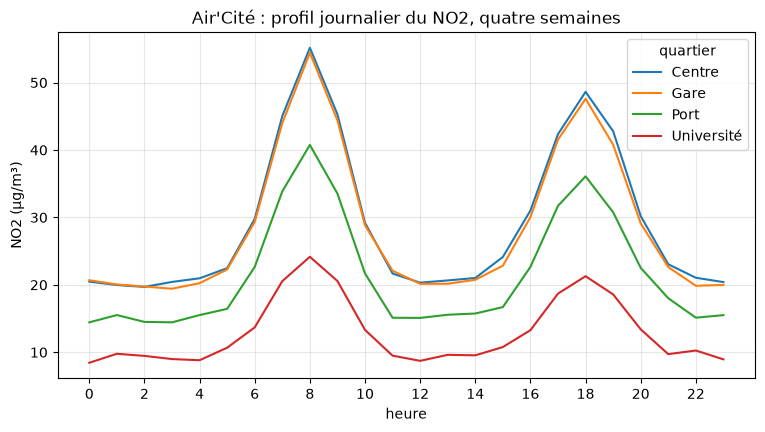

In [5]:
m["heure"] = m["horodatage"].dt.hour
profil = m.pivot_table(index="heure", columns="quartier", values="no2", aggfunc="mean")
print("Heure de pointe :", profil.mean(axis=1).idxmax(), "h")

fig, ax = plt.subplots(figsize=(9, 4.5))
profil.plot(ax=ax)
ax.set_title("Air'Cité : profil journalier du NO2, quatre semaines")
ax.set_xlabel("heure")
ax.set_ylabel("NO2 (µg/m³)")
ax.set_xticks(range(0, 24, 2))
ax.grid(alpha=.3)
fig.savefig("profil.png", dpi=120, bbox_inches="tight")

## 5. Semaine et week-end

type_jour   semaine  week-end  baisse_%
quartier                               
Centre         30.5      25.3      17.0
Gare           29.7      25.0      15.9
Port           22.5      18.8      16.4
Université     13.6      11.3      16.5


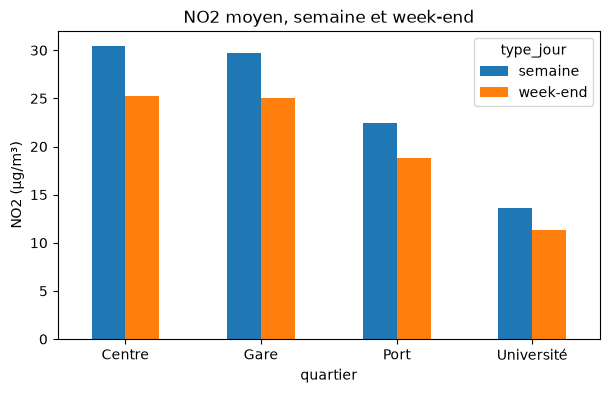

In [6]:
m["type_jour"] = m["horodatage"].dt.dayofweek.map(lambda j: "week-end" if j >= 5 else "semaine")
sw = m.pivot_table(index="quartier", columns="type_jour", values="no2", aggfunc="mean")
sw["baisse_%"] = (100 * (1 - sw["week-end"] / sw["semaine"])).round(1)
print(sw.round(1))

fig, ax = plt.subplots(figsize=(7, 4))
sw[["semaine", "week-end"]].plot.bar(ax=ax, rot=0)
ax.set_title("NO2 moyen, semaine et week-end")
ax.set_ylabel("NO2 (µg/m³)")
fig.savefig("semaine.png", dpi=120, bbox_inches="tight")

Les trois chiffres : le quartier le plus exposé, l'heure de pointe, la baisse du week-end.

In [7]:
print(f"Quartier le plus exposé : {par_quartier.index[0]} ({par_quartier['mean'].iloc[0]} µg/m³)")
print(f"Heure de pointe         : {profil.mean(axis=1).idxmax()} h")
print(f"Baisse du week-end      : {sw['baisse_%'].min()} à {sw['baisse_%'].max()} %")

Quartier le plus exposé : Centre (29.0 µg/m³)
Heure de pointe         : 8 h
Baisse du week-end      : 15.9 à 17.0 %


## Bonus 1 : moyennes journalières, un onglet Excel par quartier

In [8]:
jour = (m.set_index("horodatage").groupby("capteur")["no2"]
          .resample("D").mean().round(1).unstack("capteur"))
with pd.ExcelWriter("journalier.xlsx") as xl:
    for q, ids in cap.groupby("quartier")["id"]:
        jour[ids.tolist()].to_excel(xl, sheet_name=q)
print(jour.shape)

(28, 12)


## Bonus 2 : les mêmes questions en SQL, avec DuckDB
DuckDB lit le CSV lui-même, sans `read_csv`. `count(*)` compte les lignes, `count(no2)`
les valeurs présentes : `avg` ignore les cellules vides, comme `mean()` de pandas.

In [9]:
import duckdb

CSV = DONNEES + "mesures.csv"
print(duckdb.sql(f"DESCRIBE SELECT * FROM '{CSV}'").df()[["column_name", "column_type"]])
duckdb.sql(f"""
    SELECT quartier, round(avg(no2), 1) AS moyenne, max(no2) AS maximum,
           count(*) AS lignes, count(no2) AS mesures
    FROM '{CSV}'
    GROUP BY quartier
    ORDER BY moyenne DESC
""").df()

  column_name column_type
0  horodatage   TIMESTAMP
1     capteur     VARCHAR
2    quartier     VARCHAR
3         no2      DOUBLE
4        pm10      DOUBLE
5        temp      DOUBLE


,quartier,moyenne,maximum,lignes,mesures
0,Centre,29.0,72.5,2016,1986
1,Gare,28.4,70.8,2016,1976
2,Port,21.4,58.6,2016,1975
3,Université,13.0,38.6,2016,1976


Sur le DataFrame interpolé `m` : DuckDB le trouve par son nom de variable.
Université passe de 13,0 (fichier brut) à 12,9 : les trous comblés tombaient surtout
aux heures creuses. `.df()` rend un DataFrame pandas, qu'on compare au résultat de l'étape 3.

In [10]:
q = duckdb.sql("""
    SELECT quartier, round(avg(no2), 1) AS mean, round(max(no2), 1) AS max
    FROM m
    GROUP BY quartier
    ORDER BY mean DESC
""").df().set_index("quartier")
print(q)
assert q.equals(par_quartier)    # même réponse que pandas

            mean   max
quartier              
Centre      29.0  72.5
Gare        28.4  70.8
Port        21.4  58.6
Université  12.9  38.6


La jointure avec la table des capteurs, en SQL : `cap` est lui aussi un DataFrame.

In [11]:
duckdb.sql("""
    SELECT m.capteur, cap.nom, round(avg(m.no2), 1) AS moyenne
    FROM m JOIN cap ON m.capteur = cap.id
    GROUP BY m.capteur, cap.nom
    ORDER BY moyenne DESC
    LIMIT 3
""").df()

,capteur,nom,moyenne
0,AQ-03,Rue Neuve,31.6
1,AQ-05,Boulevard Ferroviaire,30.3
2,AQ-04,Parvis de la Gare,28.8


Semaine et week-end : `isodow` numérote les jours de 1 (lundi) à 7 (dimanche),
`FILTER` restreint chaque moyenne. On arrondit à la fin, comme à l'étape 5.

In [12]:
sw_sql = duckdb.sql("""
    WITH moy AS (
        SELECT quartier,
               avg(no2) FILTER (WHERE isodow(horodatage) <= 5) AS semaine,
               avg(no2) FILTER (WHERE isodow(horodatage) >= 6) AS week_end
        FROM m
        GROUP BY quartier
    )
    SELECT quartier, round(semaine, 1) AS semaine, round(week_end, 1) AS week_end,
           round(100 * (1 - week_end / semaine), 1) AS baisse_pct
    FROM moy
    ORDER BY quartier
""").df()
print(sw_sql)
assert (sw_sql["baisse_pct"].values == sw["baisse_%"].values).all()

     quartier  semaine  week_end  baisse_pct
0      Centre     30.5      25.3        17.0
1        Gare     29.7      25.0        15.9
2        Port     22.5      18.8        16.4
3  Université     13.6      11.3        16.5
